<a href="https://colab.research.google.com/github/aarushi18anand-ux/P300-analysis/blob/main/P300analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
## mne project on p300 odball paradigm

P300 response: a change in the EEG signal that can occur after a person notices a rare or important event. In an “oddball” task, the person sees or hears many common events and a few rare ones. We’ll compare the EEG response to those two kinds of event.

In [3]:
!pip install -q mne openneuro-py
import openneuro as on

subjects = ["sub-001", "sub-002", "sub-003", "sub-004", "sub-005", "sub-006",
            "sub-007", "sub-008", "sub-009", "sub-010", "sub-011", "sub-012", "sub-013"]


on.download(dataset="ds003061", target_dir="/content/ds003061", include=subjects)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
🌍 Preparing to download ds003061 …
📥 Checking 278 files, downloading as needed (5 concurrent downloads). 


Output()

🔄 Could not connect (DNS or network error) while downloading sub-008/eeg/sub-008_task-P300_run-1_electrodes.tsv, 
retrying (5 retries remain, backing off 0.5s) …

✅ Finished downloading ds003061 (downloaded 278 files and 2.3 GB).


In [4]:
import glob
files = sorted(glob.glob("/content/ds003061/sub-*/eeg/*_eeg.set"))
print(len(files))

39


In [5]:
import mne
import pandas as pd

def load_clean(path):
    raw = mne.io.read_raw_eeglab(path, preload=True)
    if "Temp" in raw.ch_names:
        raw.drop_channels(["Temp"])
    raw.pick("eeg")
    return raw

In [6]:
files_run2 = sorted(glob.glob("/content/ds003061/sub-*/eeg/*run-2_eeg.set"))
print(len(files_run2))

raws = {}
for path in files_run2:
    sub = path.split("/")[-1].split("_")[0]
    raws[sub] = load_clean(path)
    print(len(raws))



13


/tmp/ipykernel_1318/1329799318.py:5: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(path, preload=True)
/tmp/ipykernel_1318/1329799318.py:5: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=True)


1


/tmp/ipykernel_1318/1329799318.py:5: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(path, preload=True)
/tmp/ipykernel_1318/1329799318.py:5: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=True)


2


/tmp/ipykernel_1318/1329799318.py:5: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(path, preload=True)
/tmp/ipykernel_1318/1329799318.py:5: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=True)


... (18 outputs left out)

12


/tmp/ipykernel_1318/1329799318.py:5: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(path, preload=True)


13


/tmp/ipykernel_1318/1329799318.py:5: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=True)


Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).


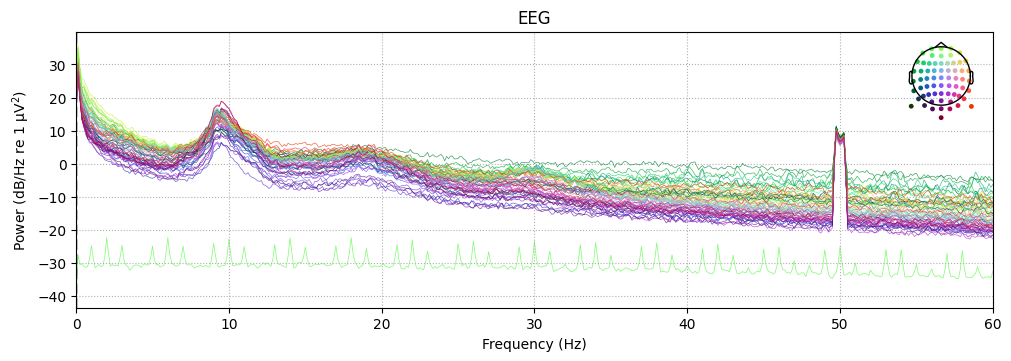

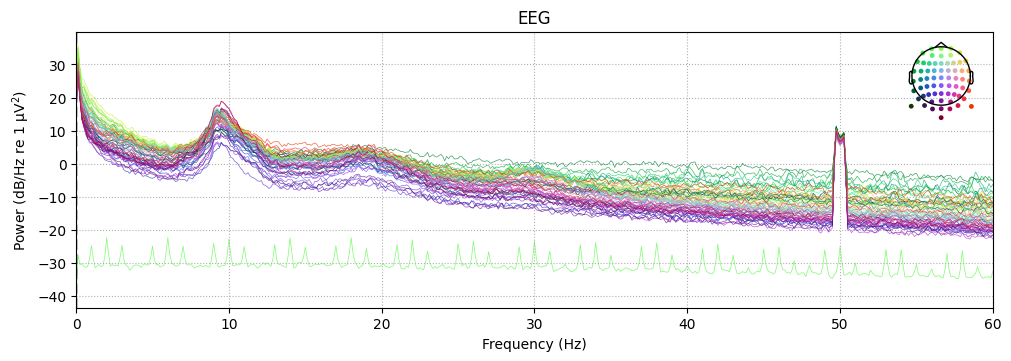

In [7]:
## filtering the signal (removing very slow drifts and fast noise, trying it on first subject)

raw_before = raws['sub-001']
raw_before.compute_psd(fmax=60).plot()


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 8449 samples (33.004 s)

Effective window size : 8.000 (s)
Plotting power spectral density (dB=True).


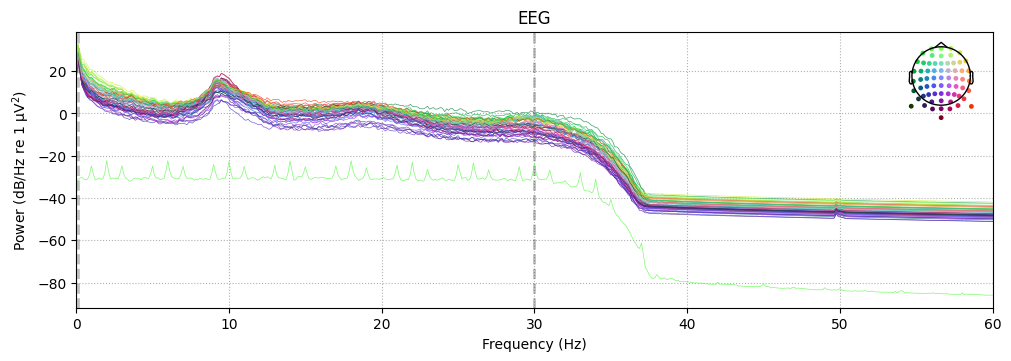

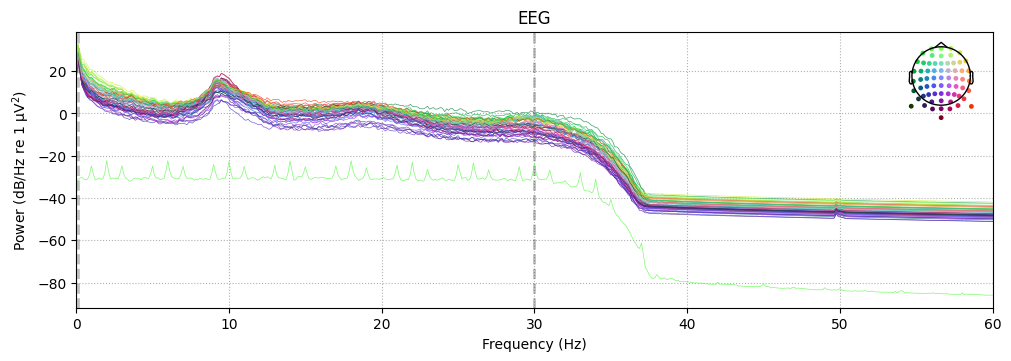

In [8]:
demo = raws["sub-001"].copy()
demo.filter(l_freq= 0.1, h_freq=30.0)
demo.compute_psd(fmax=60).plot()

In [9]:
for name in raws:
    raws[name].filter(l_freq=0.1, h_freq=30.0)
    raws[name].set_eeg_reference("average", projection=False)
    print(name, "done")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 8449 samples (33.004 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
sub-001 done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenua

In [10]:
## cutting windows around each beep

raw1 = raws["sub-001"]
rawpd1 = pd.DataFrame(raw1.annotations.description)
print(rawpd1.value_counts())


0                   
standard                527
response                112
noise                   111
oddball_with_reponse    111
noise_with_reponse        1
Name: count, dtype: int64


In [11]:
event_map = {"standard": 1, "oddball_with_reponse": 2}
events, _ = mne.events_from_annotations(raw1, event_id=event_map)
print(len(events))

Used Annotations descriptions: ['oddball_with_reponse', 'standard']
638


In [12]:
REJECT_UV = 100
epoch_ids = {"standard": 1, "oddball": 2}
reject_limit = {"eeg": REJECT_UV * 1e-6}

epochs1 = mne.Epochs(raw1, events,
                     event_id=epoch_ids,
                     tmin=-0.2, tmax=0.8,
                     baseline=(-0.2, 0),
                     reject=reject_limit,
                     preload=True)
print(epochs1)

Not setting metadata
638 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 638 events and 257 original time points ...
    Rejecting  epoch based on EEG : ['AF7', 'Fpz', 'Fp2', 'AF8', 'AF4']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['FC5']
    Rejecting  epoch based on EEG : ['FC5']
    Rejecting  epoch based on EEG : ['FC5']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['P1']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8', 'AF4', 'F6', 'F8']
    Rejecting  epoch based on EEG : ['Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['PO7', 'AF8']
    Rejecting  epoch based on EEG : ['P1']
    Rejecting  epoch based on EEG : ['Fpz', '

In [13]:
all_epochs = {}
for name in raws:
    events, _ = mne.events_from_annotations(raws[name], event_id=event_map)
    all_epochs[name] = mne.Epochs(raws[name], events,
                                  event_id=epoch_ids,
                                  tmin=-0.2, tmax=0.8,
                                  baseline=(-0.2, 0),
                                  reject=reject_limit,
                                  preload=True)
    print(name, "oddball:", len(all_epochs[name]["oddball"]),
          "standard:", len(all_epochs[name]["standard"]))

Used Annotations descriptions: ['oddball_with_reponse', 'standard']
Not setting metadata
638 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 638 events and 257 original time points ...
    Rejecting  epoch based on EEG : ['AF7', 'Fpz', 'Fp2', 'AF8', 'AF4']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['FC5']
    Rejecting  epoch based on EEG : ['FC5']
    Rejecting  epoch based on EEG : ['FC5']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['P1']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['Fpz', 'Fp2', 'AF8', 'AF4', 'F6', 'F8']
    Rejecting  epoch based on EEG : ['Fp2', 'AF8']
    Rejecting  epoch based on EEG : ['PO7', 'AF8']
    Rejecting  epoch